# ALiBi and attention distance

Attention with linear biases gives each causal head a different cost for looking further back. A neutral content score isolates what that bias does.

A head with positive slope m subtracts m times the distance from the logit of each allowed key. The four-head slope schedule follows the power-of-two construction used in ALiBi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)

## Measure how far the heads look

Evaluate the final query at two lengths. The first and last columns of the heat map correspond to distances zero and 31.

In [2]:
heads = 4
slopes = 2.0 ** (-8 * np.arange(1, heads + 1) / heads)
rows = []
for length in [12, 32]:
    distances = np.arange(length)
    weights = softmax(-slopes[:, None] * distances)
    for i, (slope, w) in enumerate(zip(slopes, weights)):
        rows.append((length, i + 1, slope, distances @ w, w[:4].sum()))
report(["Length", "Head", "Slope", "Expected distance", "Mass on nearest four"], rows)
assert np.allclose(weights.sum(1), 1)

,Length,Head,Slope,Expected distance,Mass on nearest four
0,12,1,0.25000,2.89206,0.66524
1,12,2,0.06250,4.76215,0.41923
2,12,3,0.01562,5.31391,0.35437
3,12,4,0.00391,5.45345,0.33856
4,32,1,0.25000,3.51007,0.63233
5,32,2,0.06250,10.49664,0.25582
6,32,3,0.01562,14.17349,0.15398
7,32,4,0.00391,15.16708,0.13194


## Read the distance preference

All four heads see the same flat content logits. The only difference between their distributions is the slope.

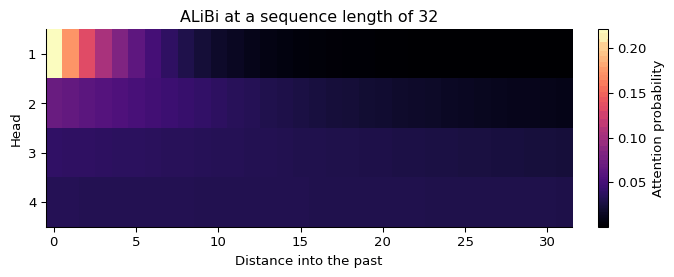

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
im = ax.imshow(weights, aspect="auto", cmap="magma")
ax.set(
    xlabel="Distance into the past",
    ylabel="Head",
    title="ALiBi at a sequence length of 32",
    yticks=range(heads),
    yticklabels=range(1, heads + 1),
)
fig.colorbar(im, ax=ax, label="Attention probability")
plt.show()

## Interpreting the result

A steep slope concentrates probability near the current token. A trained model adds learned content scores, so the slopes alone cannot predict its attention map.

## Exercise

Give a distant key a logit advantage of two. For which heads does it overtake the current token?

## References

[Press, Smith and Lewis (2022), Train Short, Test Long](https://arxiv.org/abs/2108.12409)